# 03 - Proximity analysis
Straight-line distances from every building to the nearest feature of each OSM layer, counts within buffers, green area within 500 m and normalised (0-1, 1 = better) versions of every variable.

In [1]:
import os
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import contextily as cx

## Load layers and project to UTM 21S (metres)

In [2]:
CRS = 32721
gp = "data/geopackage"

bld = gpd.read_file("data/buildings_aoi.gpkg").to_crs(CRS)
amenities = gpd.read_file(f"{gp}/amenities.gpkg").to_crs(CRS)
coast = gpd.read_file(f"{gp}/coast_beaches.gpkg").to_crs(CRS)
green = gpd.read_file(f"{gp}/green_areas.gpkg").to_crs(CRS)
transport = gpd.read_file(f"{gp}/public_transport.gpkg").to_crs(CRS)
streets = gpd.read_file(f"{gp}/street_network.gpkg", layer="edges").to_crs(CRS)

coastline = coast[coast["natural"] == "coastline"]
beaches = coast[coast["natural"] == "beach"]
parks = green[green["leisure"].isin(["park", "garden", "playground"]) | (green["place"] == "square")]

print(len(bld), "buildings |", len(parks), "parks")

78359 buildings | 65 parks


## Nearest-feature distances (building polygon → nearest geometry)

In [3]:
def nearest(layer, col):
    j = gpd.sjoin_nearest(bld[["geometry"]], layer[["geometry"]], distance_col=col)
    return j[~j.index.duplicated()][col]

for layer, col in [(amenities, "dist_amenity_m"), (coastline, "dist_coastline_m"), (beaches, "dist_beach_m"),
                   (green, "dist_green_m"), (transport, "dist_transport_m"), (streets, "dist_street_m")]:
    bld[col] = nearest(layer, col).round(1)

## Buffer analysis (from building centroids)

In [4]:
cent = bld.geometry.centroid
buf500 = gpd.GeoDataFrame(geometry=cent.buffer(500), crs=CRS)
buf400 = gpd.GeoDataFrame(geometry=cent.buffer(400), crs=CRS)

def count_within(buf, layer):
    j = gpd.sjoin(buf, layer[["geometry"]], predicate="intersects")
    return j.groupby(level=0).size().reindex(bld.index, fill_value=0)

bld["parks_500m"] = count_within(buf500, parks)
bld["amenities_500m"] = count_within(buf500, amenities)
bld["bus_stops_400m"] = count_within(buf400, transport)

In [5]:
# Green area (m2) inside the 500 m buffer; dissolve first so overlapping polygons are not double counted
green_parts = green[["geometry"]].dissolve().explode(index_parts=False).reset_index(drop=True)
j = gpd.sjoin(buf500, green_parts, predicate="intersects")
inter = j.geometry.intersection(green_parts.geometry.loc[j["index_right"]], align=False).area
bld["green_m2_500m"] = inter.groupby(level=0).sum().reindex(bld.index, fill_value=0).round(0)

## Normalisation
Clip each variable at its 95th percentile, min-max scale to 0-1 and invert distances so that 1 is always better.

In [6]:
dist_cols = ["dist_amenity_m", "dist_coastline_m", "dist_beach_m", "dist_green_m", "dist_transport_m", "dist_street_m"]
pos_cols = ["parks_500m", "amenities_500m", "bus_stops_400m", "green_m2_500m"]

for c in dist_cols + pos_cols:
    x = bld[c].clip(upper=bld[c].quantile(0.95))
    x = (x - x.min()) / (x.max() - x.min())
    bld[f"n_{c}"] = (1 - x if c in dist_cols else x).round(4)

bld[dist_cols + pos_cols].describe().round(1)

,dist_amenity_m,dist_coastline_m,dist_beach_m,dist_green_m,dist_transport_m,dist_street_m,parks_500m,amenities_500m,bus_stops_400m,green_m2_500m
count,78359.0,78359.0,78359.0,78359.0,78359.0,78359.0,78359.0,78359.0,78359.0,78359.0
mean,654.3,2516.4,2452.8,158.0,343.0,18.1,1.1,2.7,2.8,55495.9
std,565.7,1510.6,1512.2,111.1,297.3,12.0,1.5,5.3,3.1,56265.5
min,0.0,12.9,1.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,242.4,1289.8,1217.7,71.5,141.8,10.4,0.0,0.0,0.0,18608.0
50%,499.9,2487.7,2423.9,137.2,259.3,15.2,0.0,0.0,2.0,42494.0
75%,875.5,3583.4,3522.5,221.5,452.2,24.1,2.0,3.0,4.0,68651.0
max,3121.3,7638.5,7588.2,854.7,2385.4,328.5,9.0,42.0,17.0,682378.0


## Export

In [7]:
os.makedirs("output", exist_ok=True)
bld.to_crs(4326).to_file("output/buildings_proximity.gpkg", layer="buildings", driver="GPKG")

## Maps (building centroids coloured by quantile class, source features in red)

C:\Users\guillermo\Documents\agentic_livability_score\.venv\Lib\site-packages\mapclassify\classifiers.py:1767: UserWarning: Not enough unique values in array to form 5 classes. Setting k to 4.
  self.bins = quantile(y, k=k)


C:\Users\guillermo\Documents\agentic_livability_score\.venv\Lib\site-packages\mapclassify\classifiers.py:1767: UserWarning: Not enough unique values in array to form 5 classes. Setting k to 4.
  self.bins = quantile(y, k=k)


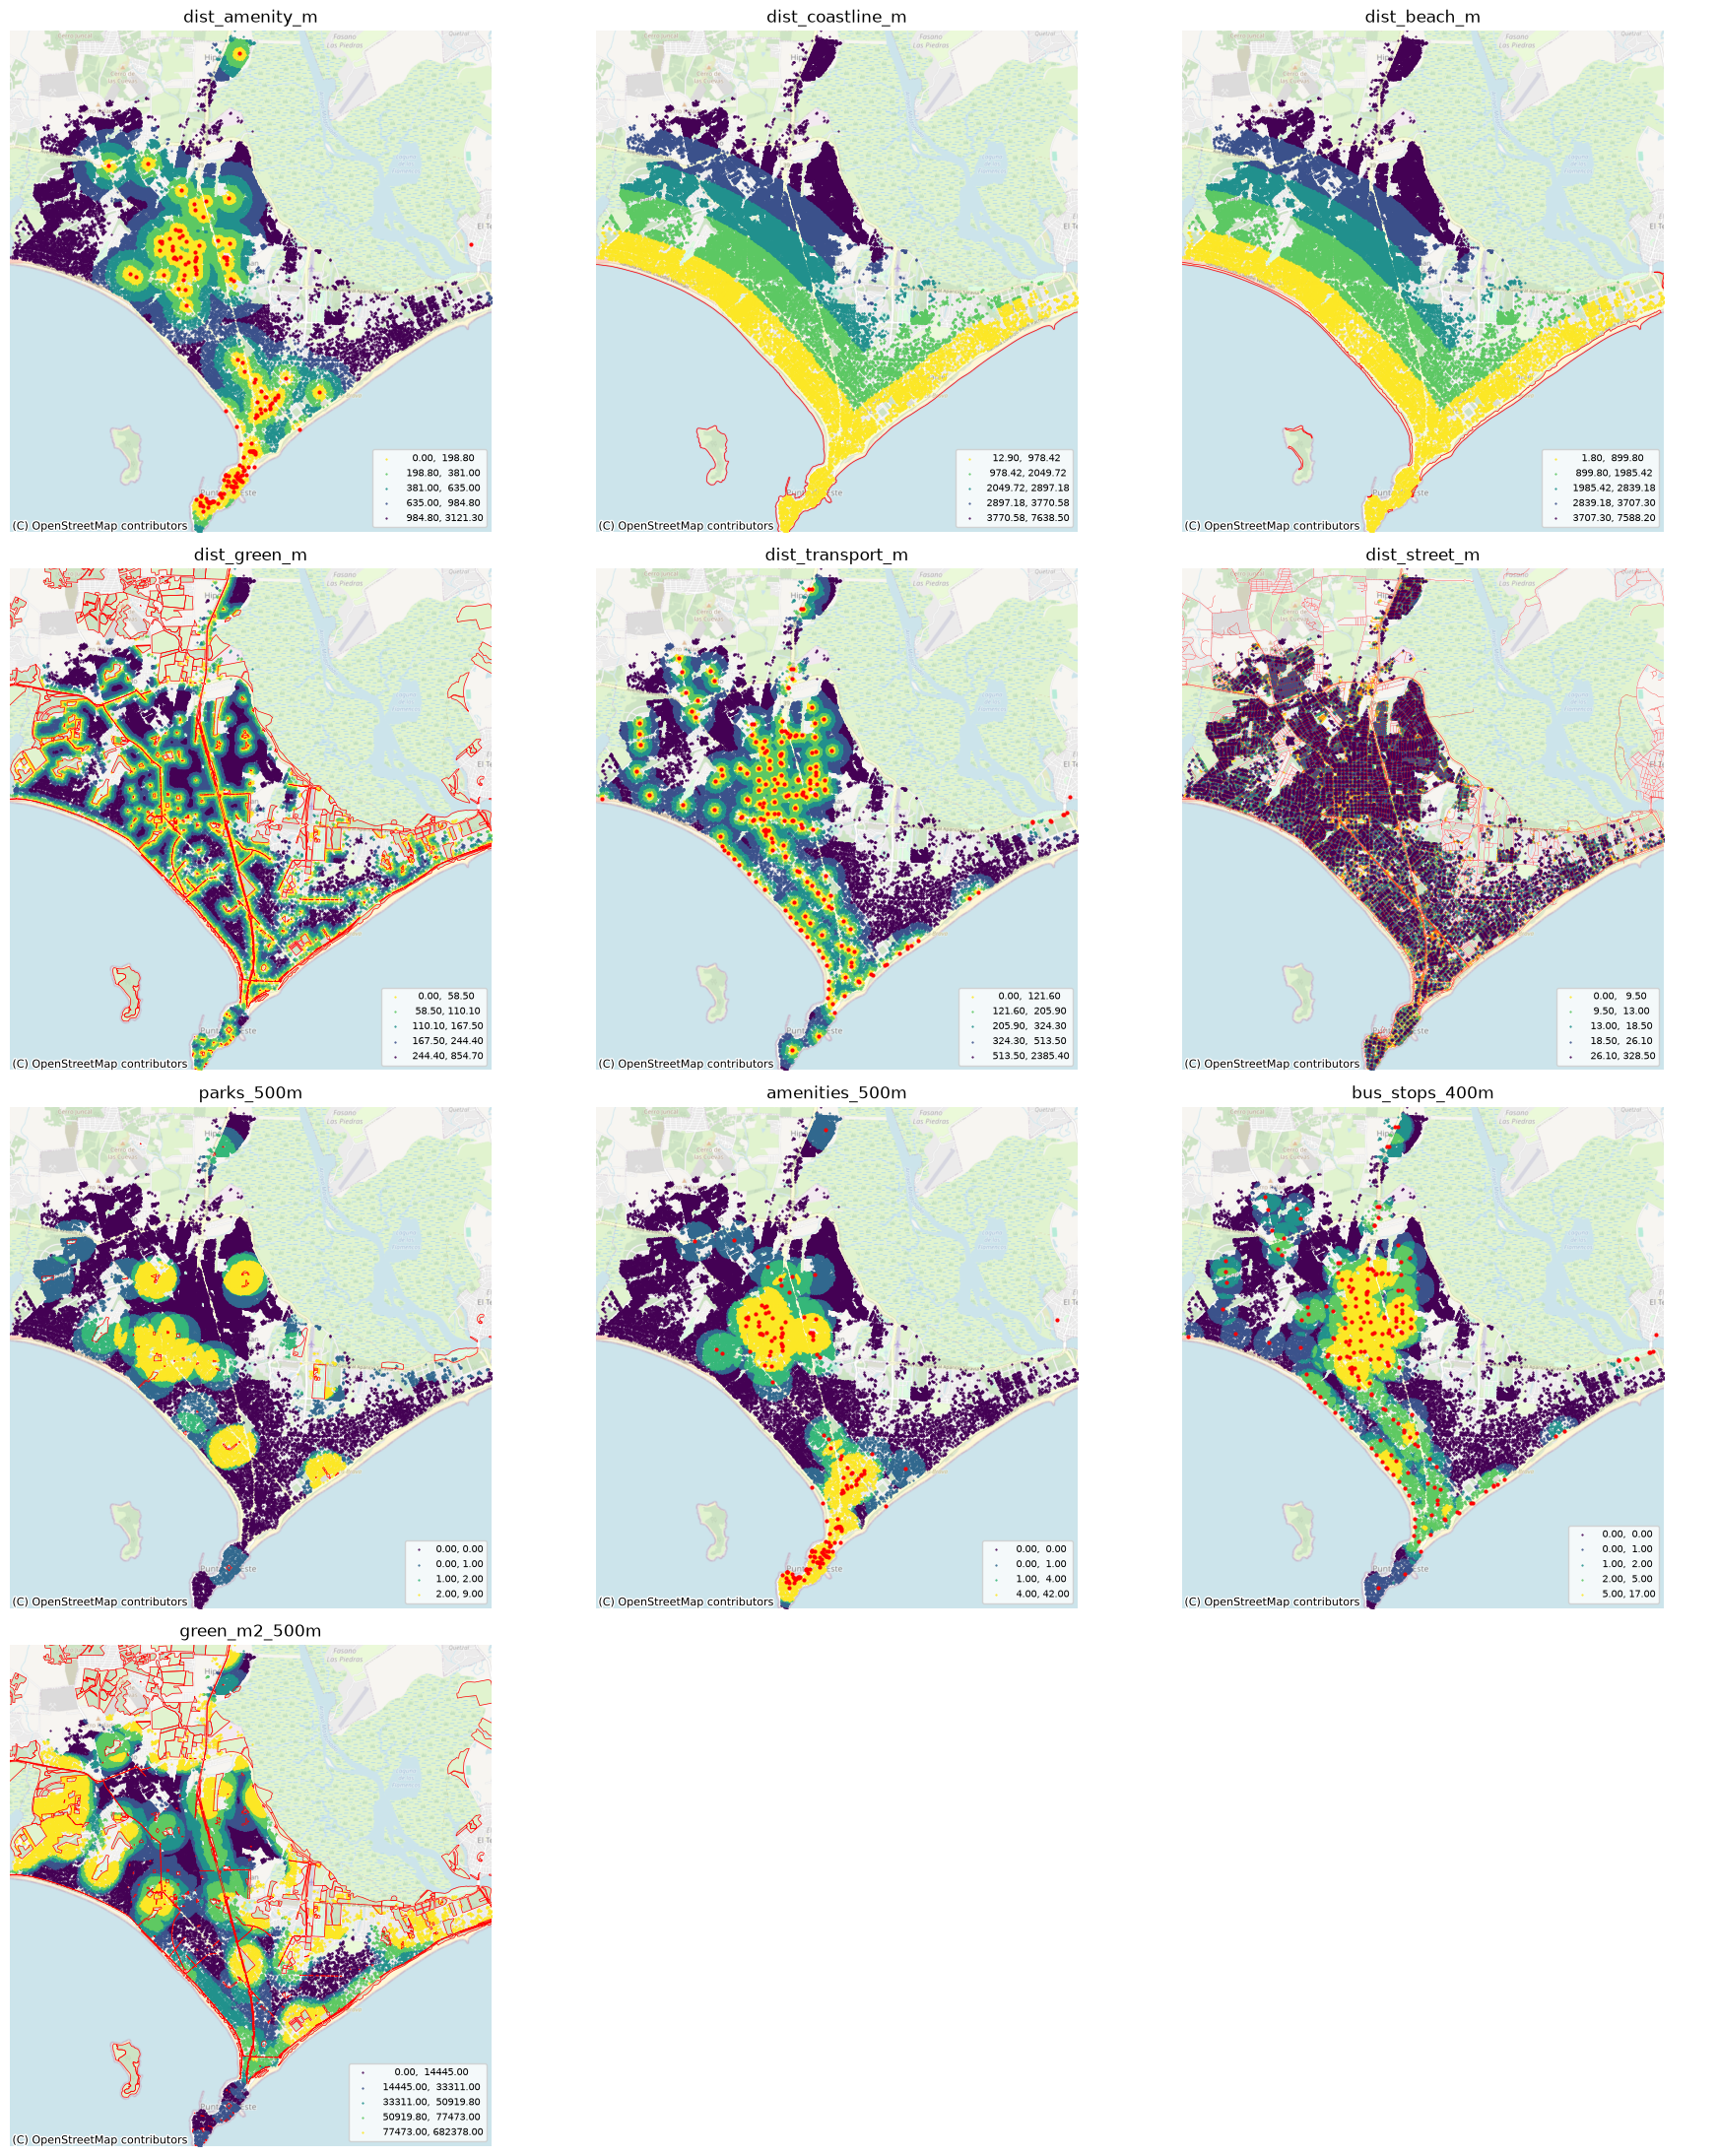

In [8]:
# OSM tile servers block the default client User-Agent
cx.tile.USER_AGENT = "livability-score-notebook/1.0"
# Web Mercator so the OSM basemap needs no reprojection
pts = bld.set_geometry(cent).to_crs(3857)
maps = [("dist_amenity_m", amenities), ("dist_coastline_m", coastline), ("dist_beach_m", beaches),
        ("dist_green_m", green), ("dist_transport_m", transport), ("dist_street_m", streets),
        ("parks_500m", parks), ("amenities_500m", amenities), ("bus_stops_400m", transport),
        ("green_m2_500m", green)]

fig, axes = plt.subplots(4, 3, figsize=(18, 22))
for ax, (col, src) in zip(axes.flat, maps):
    cmap = "viridis_r" if col.startswith("dist") else "viridis"
    pts.plot(column=col, ax=ax, markersize=0.3, cmap=cmap, scheme="quantiles", k=5,
             legend=True, legend_kwds={"loc": "lower right", "fontsize": 7})
    if src is amenities or src is transport:
        src.centroid.to_crs(3857).plot(ax=ax, color="red", markersize=4)
    else:
        g = src.to_crs(3857).geometry
        g = g.where(~g.geom_type.str.contains("Polygon"), g.boundary)
        g.plot(ax=ax, color="red", linewidth=0.2 if src is streets else 0.5)
    ax.set_xlim(*pts.total_bounds[[0, 2]]); ax.set_ylim(*pts.total_bounds[[1, 3]])
    cx.add_basemap(ax, source=cx.providers.OpenStreetMap.Mapnik, alpha=0.6)
    ax.set_title(col); ax.set_axis_off()
for ax in axes.flat[len(maps):]:
    ax.set_axis_off()
plt.tight_layout()